# PH5720 — Problem Set 2
**Department of Physics | IIT Madras | January–May 2025**


## Question 1 — Maximum and Minimum of a List

Create a list of 10 integer numbers and find the maximum and minimum numbers from that list, without using any Python module.


In [29]:
import numpy as np
import random as rd
c=[]
for i in range(10):
    c.append(rd.randint(0,1000))
max=c[0]
min=c[0]
for i in c:
    if i>max:
        max=i
    if i<min:
        min=i
print('input array->',c) 
print('max',max)
print('min',min)
       


input array-> [410, 606, 929, 886, 688, 511, 364, 847, 81, 511]
max 929
min 81


## Question 2 — Smallest Representable Positive Number

Write Python code to determine the smallest positive number that can be represented on the computer you are using for different data types, e.g., `float64` and `float128`.


In [2]:
import numpy as np
x=np.float64(1)
f=0
while x!=0:
    x=x/2
    f=f+1
print(np.float64(2**(-f+1)))

0.0


## Question 3 — Reverse the Digits of a Number

Write a Python program to reverse the digits of a given number.

In [33]:
x=int(input("Enter a number: "))
print('given number',x)
m=[]
while x>0:
    z=x%10
    x=x//10
    m.append(z)
m.reverse()
#print(m)

s=0
for i in range(len(m)):
    s=s+m[i]*(10**i)
print('reversed number',s)
    

given number 765876875
reversed number 578678567


## Question 4 — Prime Numbers Below 100

Print all prime numbers less than 100.

In [1]:

def prime_checker(x):
    if x<1:
        return 'invalid input'
    if x<=2:
        return True
    else:
        for i in range(2,int(x**0.5)+1):
            if x%i==0:
                return False
    return True
x=[]
for i in range(1,101):
    if prime_checker(i):
        x.append(i)
print(x)

    



[1, 2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73, 79, 83, 89, 97]


# Question 5 — Numerical Cancellation and Fractional Error

Evaluate the expression

$$ \sqrt{x^2+1}-1 $$

in two ways:

**(a)** Direct evaluation:

$$ \sqrt{x^2+1}-1 $$

**(b)** Using the equivalent expression:

$$ \frac{x^2}{\sqrt{x^2+1}+1} $$

For small values of $x$, namely $x=0.1$, $0.01$, and $0.001$, determine the fractional error in both methods of performing the subtraction.

Which method is superior, and why?

In [55]:
import numpy as np
import mpmath
# Small x values
x_values = np.array([0.1, 0.01, 0.001], dtype=np.float64)

# Method (a): Direct Computation
f_a = np.sqrt(x_values**2 + 1) - 1

# Method (b): Rationalized Computation
f_b = (x_values**2) / (np.sqrt(x_values**2 + 1) + 1)

# High precision reference using arbitrary precision library

mpmath.mp.dps = 50  # Set precision to 50 decimal places
f_true = np.array([mpmath.sqrt(x**2 + 1) - 1 for x in x_values], dtype=np.float64)

# Compute Fractional Errors
error_a = np.abs((f_true - f_a) / f_true)
error_b = np.abs((f_true - f_b) / f_true)

# Print Results
for i in range(len(x_values)):
    print(f"x = {x_values[i]:.6f}")
    print(f"  Direct Method (a): {f_a[i]:.16f}, Fractional Error: {error_a[i]:.2e}")
    print(f"  Rationalized Method (b): {f_b[i]:.16f}, Fractional Error: {error_b[i]:.2e}")
    print()


x = 0.100000
  Direct Method (a): 0.0049875621120890, Fractional Error: 1.63e-14
  Rationalized Method (b): 0.0049875621120890, Fractional Error: 8.70e-16

x = 0.010000
  Direct Method (a): 0.0000499987500624, Fractional Error: 1.88e-12
  Rationalized Method (b): 0.0000499987500625, Fractional Error: 1.10e-13

x = 0.001000
  Direct Method (a): 0.0000004999998751, Fractional Error: 2.00e-10
  Rationalized Method (b): 0.0000004999998750, Fractional Error: 8.23e-11



**Conclusion:** as error decreases for method b for smaller values of x, method b is superior

## Question 6 — Error Propagation in a Recurrence Relation

It is desired to calculate all integral powers of the number

$$
x=\frac{\sqrt{5}-1}{2}.
$$

The integral powers of $x$ satisfy the recursive relation

$$
x^{n+1}=x^{n-1}-x^n.
$$

Estimate the error by calculating the powers using the recurrence relation and comparing them with the actual values for $n=1$ to $50$.

Plot the error as a function of $n$.

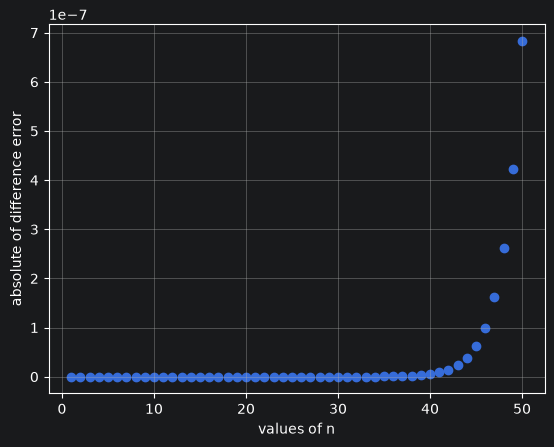

0.3819660112501051


In [6]:
import matplotlib.pyplot as plt
memory = {}
n=50
l=0
X=[]
Y=[]
x1 = ((5 ** 0.5) - 1) / 2

def f(x, n):
    if n in memory:  # Correct way to check memoization
        return memory[n]
    if n == 0:
        return 1
    elif n == 1:
        return x
    else:
        z = -f(x, n-1) + f(x, n-2)  
        memory[n]=z 
        return z
for i in range(1,n+1):
    x_r=x1**(i)
    err=abs(f(x1,i)-x_r)
    l=l+1
    Y.append(err)
    X.append(l)
plt.scatter(X,Y)
plt.xlabel('values of n')
plt.ylabel('absolute of difference error')

plt.grid()
plt.show()
print(f(x1, 2)) 


## Question 7 — Error Propagation for Powers of One-Third

Given

$$
x_n=\left(\frac{1}{3}\right)^n,
$$

it turns out that the integral powers of $1/3$ satisfy the recursive relation

$$
x_{n+1}=\frac{13}{3}x_n-\frac{4}{3}x_{n-1},
$$

with initial conditions

$$
x_0=1,\qquad x_1=\frac{1}{3}.
$$

Estimate the error by calculating the values from the recurrence relation and comparing them with the actual values for $n=1$ to $50$.

Plot the error as a function of $n$.


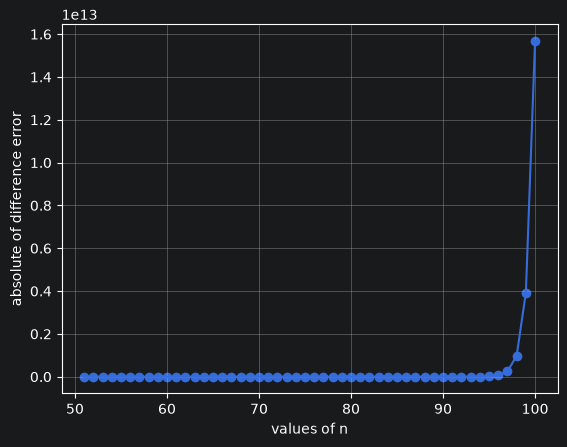

In [7]:
x1=1/3
n=50
memory1={}
X=[]
Y=[]
def f(x,n):
    if n in memory1:
        return memory1[n]
    if n == 0:
        return 1
    elif n == 1:
        return x
    else:
        z=(13/3)*f(x,n-1)-(4/3)*f(x,n-2)
        memory1[n]=z
        return z
for i in range(1,n+1):
    x_r=x1**(i)
    err=abs(f(x1,i)-x_r)
    l=l+1
    Y.append(err)
    X.append(l)
plt.scatter(X,Y)
plt.plot(X,Y)
plt.xlabel('values of n')
plt.ylabel('absolute of difference error')

plt.grid()
plt.show()


## Question 8 — Floating-Point Summation and Dot Product

Compute the dot product of the following two vectors:

$$
\begin{aligned}
\mathbf{x} = [&2.718281823,\,-3.141592654,\,1.414213562,\\
              &0.5772156649,\,0.3010299957]
\end{aligned}
$$

$$
\mathbf{y}=[1486.2497,\,878366.9879,\,-22.37492,\,4773714.647,\,0.000185049]
$$

Compute the summation in four ways:

1. **Forward order:** Sum $x_i y_i$ for $i=1,\ldots,n$.
2. **Reverse order:** Sum $x_i y_i$ for $i=n,\ldots,1$.
3. **Largest to smallest:** Add positive numbers from largest to smallest, then add negative numbers from smallest to largest, and finally add the two partial sums.
4. **Smallest to largest:** Reverse the order of adding in the previous method.

Use both single and double precision for a total of eight answers.


#### single precision (32 bit)

In [8]:
import numpy as np

# Define x and y as float32 arrays
x = np.array([2.718281823, -3.141592654, 1.414213562, 0.5772156649, 0.3010299957], dtype=np.float32)
y = np.array([1486.2497, 878366.9879, -22.37492, 4773714.647, 0.000185049], dtype=np.float32)

# Compute element-wise products
M = x * y  # Stores xi * yi terms

# Forward order summation
forward_sum = np.sum(M)

# Reverse order summation
reverse_sum = np.sum(M[::-1])

# Smallest to largest order summation
M_sorted_smallest = np.sort(M)  # Sort in ascending order
smallest_to_largest_sum = np.sum(M_sorted_smallest)

# Largest to smallest order summation
M_sorted_largest = np.sort(M)[::-1]  # Sort in descending order
largest_to_smallest_sum = np.sum(M_sorted_largest)

# Print results
print("Forward sum =", forward_sum)
print("Reversed sum =", reverse_sum)
print("Smallest to Largest order =", smallest_to_largest_sum)
print("Largest to Smallest order =", largest_to_smallest_sum)


Forward sum = -0.4999443
Reversed sum = -0.4543457
Smallest to Largest order = -0.5
Largest to Smallest order = -0.5


#### Double precision (64 bit)

In [9]:
import numpy as np

# Define x and y as float64 arrays
x = np.array([2.718281823, -3.141592654, 1.414213562, 0.5772156649, 0.3010299957], dtype=np.float64)
y = np.array([1486.2497, 878366.9879, -22.37492, 4773714.647, 0.000185049], dtype=np.float64)

# Compute element-wise products
M = x * y  # Stores xi * yi terms

# Forward order summation
forward_sum = np.sum(M)

# Reverse order summation
reverse_sum = np.sum(M[::-1])

# Smallest to largest order summation
M_sorted_smallest = np.sort(M)  # Sort in ascending order
smallest_to_largest_sum = np.sum(M_sorted_smallest)

# Largest to smallest order summation
M_sorted_largest = np.sort(M)[::-1]  # Sort in descending order
largest_to_smallest_sum = np.sum(M_sorted_largest)

# Print results
print("Forward sum =", forward_sum)
print("Reversed sum =", reverse_sum)
print("Smallest to Largest order =", smallest_to_largest_sum)
print("Largest to Smallest order =", largest_to_smallest_sum)

Forward sum = -7.431385965330528e-06
Reversed sum = -7.431405265378999e-06
Smallest to Largest order = -7.431488484144211e-06
Largest to Smallest order = -7.431488484144211e-06


## Question 9 — Electric Field Lines of Two Point Charges

Plot the electric field lines for two point charges:

- $q=+1$ at $(+1,0)$
- $q=-1$ at $(-1,0)$

## Question 10 — Electric Field Lines of Four Point Charges

Plot the electric field lines for four point charges:

- $q=+1$ at $(-1,0)$
- $q=+1$ at $(1,0)$
- $q=-1$ at $(0,1)$
- $q=-1$ at $(0,-1)$

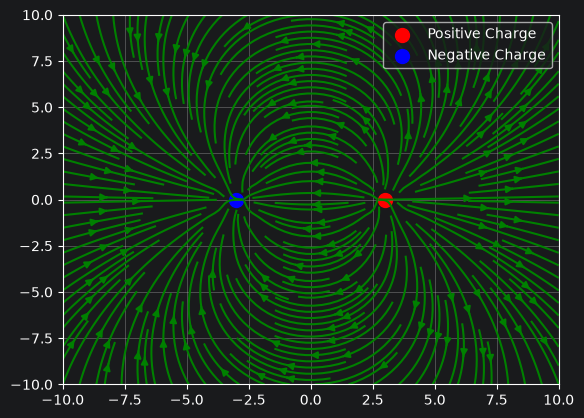

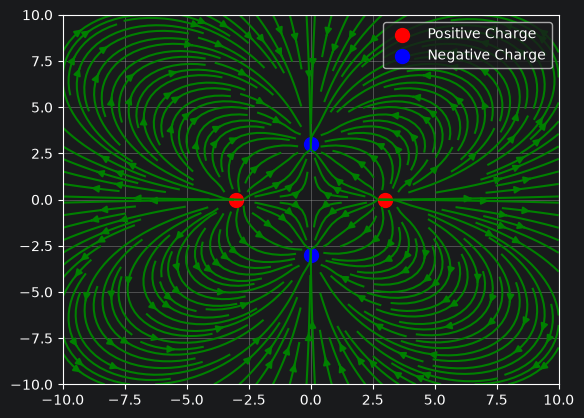

In [10]:
import numpy as np
import matplotlib.pyplot as plt
f=10
i=-f
step=30
fz=1
epsilon=1e-10
x=np.linspace(i,f,step)
y=np.linspace(i,f,step)
(x,y)=np.meshgrid(x,y)
a=3
f1=(((x+a)**2)+(y**2)+epsilon)**(-1.5)
f3=(((y+a)**2)+(x**2)+epsilon)**(-1.5)
f2=(((x-a)**2)+(y**2)-epsilon)**(-1.5)
f4=(((y-a)**2)+(x**2)-epsilon)**(-1.5)

#Q.9
X=fz*(((-x-a)*f1)+((x-a)*f2))
Y=y*(-f1+f2)*fz
plt.streamplot(x,y,X,Y,density=2,color='g')
plt.scatter([a],[0],c='r', label='Positive Charge', s=100)
plt.scatter([-a],[0],c='b', label='Negative Charge', s=100)
plt.legend()
plt.grid(True)
plt.show()

#Q10
X1=fz*(-((-x-a)*f1)+((x-a)*f2))
Y2=fz*(((-y-a)*f3)-((y-a)*f4))
Y1=y*(f1+f2)*fz
X2=x*(-f3-f4)*fz
X=X1+X2
Y=Y1+Y2
plt.streamplot(x,y,X,Y,density=2,color='g')
plt.scatter([a,-a],[0,0],c='r', label='Positive Charge', s=100)
plt.scatter([0,0],[a,-a],c='b', label='Negative Charge', s=100)
plt.legend()
plt.grid(True)
plt.show()

## Question 11 — Interference of Two Wave Sources

Assume that the combined effect of two objects dropped in a water basin can be modeled by

$$
W(\mathbf{r}) =
A\sin\left(k|\mathbf{r}-\mathbf{r}_0|\right)
+
A\sin\left(k|\mathbf{r}-\mathbf{r}_1|\right).
$$

For simplicity, take

$$
A=1,\qquad k=\frac{2\pi}{0.3},
$$

with source positions

$$
\mathbf{r}_0=(-1,0),\qquad \mathbf{r}_1=(1,0).
$$

Plot the resultant waveform in the $x$-$y$ plane, with both axes extending from $-4$ to $4$.


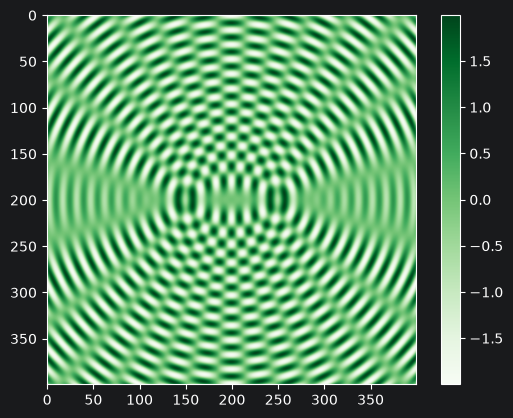

In [11]:
f=4
i=-f
step=400
x=np.linspace(i,f,step)
y=np.linspace(i,f,step)
(x,y)=np.meshgrid(x,y)
a=1
A=1
k=2*np.pi/0.3
epsilon=0.1
f1=(((x+a)**2)+(y**2)+epsilon)**(0.5)
f2=(((x-a)**2)+(y**2)+epsilon)**(0.5)
f=A*(np.sin(k*f1)+np.sin(k*f2))
plt.imshow(f,cmap='Greens')
plt.colorbar(cmap=plt.get_cmap('Greens'))
plt.show()

## Question 12 — Phase-Space Contours of a Pendulum

The total energy of a pendulum of mass $m$ and length $l$ is

$$
E=\frac{1}{2}ml^2\dot{\theta}^{\,2}
+mgl(1-\cos\theta).
$$

Plot $\dot{\theta}$ versus $\theta$ and show the contours of constant energy using Matplotlib's `contour()` function.

Use the following parameters:

- $\theta$ varying from $-2\pi$ to $+2\pi$
- $m=1\,\mathrm{kg}$
- $l=1\,\mathrm{m}$
- $g=9.8\,\mathrm{m/s^2}$

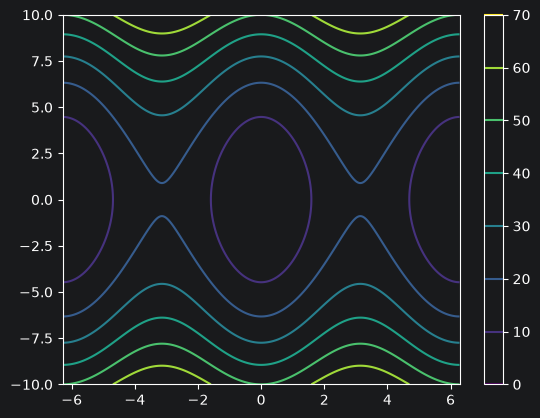

In [12]:
import numpy as np
import matplotlib.pyplot as plt
theta_f=2*np.pi
theta_i=-theta_f
f=10
i=-f
theta=np.linspace(theta_f,theta_i,1000)
p=np.linspace(i,f,1000)
theta,p=np.meshgrid(theta,p)
g=9.8
m=1
l=1

f=0.5*m*(l**2)*(p**2)+m*g*l*(1-np.cos(theta))
plt.contour(theta,p,f)
plt.colorbar()
plt.show()
